# 1. Intro

URL Dataset: https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction

Problem: 
Penyakit kardiovaskular (Cardiovascular Diseases)/CVD merupakan penyebab kematian paling umum di dunia. Setiap tahunnya, sekitar 17.9 juta jiwa mengalami kematian disebabkan oleh penyakit ini [1]. Secara statistik, sekitar satu pertiga dari kematian yang disebabkan oleh penyakit ini terjadi pada orang berusia di bawah 70 tahun. Hal ini cukup memprihatinkan karena rata-rata angka harapan hidup di dunia beberapa tahun terakhir berada di angka sekitar 73 tahun [2]. Oleh karena itu, mengidentifikasi orang dengan potensi terkena penyakit CVD seperti gagal jantung diharapkan dapat meminimalsir angka kematian prematur (di bawah 73 tahun) dengan memastikan pengobatan yang tepat untuk penderita penyakit tersebut [1]. Program yang akan dibuat kali ini bertujuan untuk memprediksi apakah seseorang berpotensi terkena gagal jantung atau tidak. Dengan begitu, orang dengan potensi gagal jantung dapat segera berkonsultasi dengan dokter agar dilakukan penanganan yang tepat. Sementara itu, orang yang tidak berpotensi gagal jantung tetap dianjurkan untuk rutin berolahraga dan menjaga pola hidup sehat [3].

Justifikasi:
[1] https://www.who.int/health-topics/cardiovascular-diseases#tab=tab_1
[2] https://www.macrotrends.net/global-metrics/countries/wld/world/life-expectancy
[3] https://www.cdc.gov/heart-disease/prevention/index.html

User/pengguna:
Masyarakat yang ingin mengetahui apakah ia memiliki potensi penyakit jantung atau tidak

# 2. Import Libraries

Bagian ini hanya akan mengimport library yang digunakan dalam notebook

In [40]:
#Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pointbiserialr, chi2_contingency, f_oneway
from sklearn.model_selection import train_test_split, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder
from sklearn.model_selection import GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import classification_report
import pickle

# 3. Data Loading

Bagian ini membaca data csv dan menyimpannya dalam dataframe

In [2]:
# Load data
df = pd.read_csv("heart.csv")

# tampilkan 10 data pertama
df.head(10)

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0
5,39,M,NAP,120,339,0,Normal,170,N,0.0,Up,0
6,45,F,ATA,130,237,0,Normal,170,N,0.0,Up,0
7,54,M,ATA,110,208,0,Normal,142,N,0.0,Up,0
8,37,M,ASY,140,207,0,Normal,130,Y,1.5,Flat,1
9,48,F,ATA,120,284,0,Normal,120,N,0.0,Up,0


Data berhasil disimpan ke dalam dataframe. Selanjutnya akan dilihat informasi rangkuman data

In [3]:
# Informasi data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


Data terdiri dari 918 baris dan 12 kolom dengan 6 kolom bertipe data integer, 5 data bertipe data object, dan 1 data bertipe data float. Jika dilihat semua kolom memiliki 918 data non-null yang berarti tidak ada missing value. Namun akan di cek ulang untuk memastikan bahwa benar tidak ada missing value pada data

In [4]:
# Cek missing value
df.isnull().sum()

Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

Data tidak memiliki missing value. Selanjutnya akan di cek apakah terdapat data yang duplikat

In [5]:
# Cek data duplikat
df.duplicated().sum()

0

Tidak ada data yang duplikat, berarti tidak ada informasi yang redundan

# 4. Exploratory Data Analysis (EDA)

Pada bagian EDA, akan dilihat korelasi dari masing-masing fitur terhadap target (HeartDisease). Adapun jenis data fitur terbagi menjadi numerik dan kategorik:

**Fitur Numerik**:
- Age
- RestingBP
- Cholesterol
- MaxHR
- Oldpeak

 **catatan**: meskipun FastingBS bertipe data integer, namun data tersebut tergolong kategorik (value = 1 -> FastingBS > 10 mg/dl, value = 0 -> lainnya)

**Fitur Kategorik**:
- Sex
- ChestPainType
- FastingBS
- RestingECG
- ExerciseAngina
- ST_Slope

## 4.1. Korelasi Fitur Numerik dengan Target

Untuk fitur numerik, uji korelasi dilakukan menggunakan point biserial correlation. Uji statistik point biserial cocok untuk hubungan antara variabel biner dan juga variabel numerik ([Bonett G., 2020](https://pubmed.ncbi.nlm.nih.gov/31565811/)). Berikut hipotesis untuk uji statistik ini:

H0: Tidak ada korelasi atau hubungan antara target dengan fitur numerik \
H1: Ada korelasi atau hubungan antara fitur numerik dengan target

Pada uji korelasi ini H0 ditolak jika p-value < 0.05

In [6]:
# uji korelasi fitur numerik dengan target (HeartDisease)

# list kosong untuk nantinya menyimpan hasil interpretasi masing-masing kolom numerik dengan target
interpretasi = []

# definisikan kolom numerik apa saja
numerical = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']

# mengecek korelasi 
for col in numerical:

    corr_coef, p_value = pointbiserialr(df['HeartDisease'], df[col])

    if p_value < 0.05:
        interpretasi.append("ada korelasi")
    else:
        interpretasi.append("tidak ada korelasi")

# dataframe untuk menyimpan nama kolom hasil interpretasi
pd.DataFrame({'nama kolom': numerical,
              'hasil': interpretasi})

,nama kolom,hasil
0,Age,ada korelasi
1,RestingBP,ada korelasi
2,Cholesterol,ada korelasi
3,MaxHR,ada korelasi
4,Oldpeak,ada korelasi


## 4.2. Korelasi Fitur Kategorik dengan Target

Untuk fitur kategorik, uji korelasi dilakukan menggunakan [Chi-Squared](https://adatawinter.site.wesleyan.edu/schedule-2/chi-square-and-correlation/) test dengan hipotesis:

H0: Kedua variabel independen (Tidak ada hubungan) \
H1: Kedua variabel dependen (Terdapat hubungan)

Pada uji hipotesis ini H0 ditolak jika p-value < 0.05

In [7]:
# uji korelasi fitur kategorik dengan target

# list kosong untuk nantinya menyimpan hasil interpretasi masing-masing kolom kategorik dengan target
interpretasi = []

# definisikan kolom kategorik apa saja
categorical = ['Sex', 'ChestPainType', 'FastingBS', 'RestingECG', 'ExerciseAngina', 'ST_Slope']

# loop untuk tiap kolom kategorikal
for col in categorical:
    # mendefinisikan tabel contingency untuk dua variabel kategorik (fitur kategorik & target)
    contingency = pd.crosstab(df[col], df['HeartDisease'])

    # mengecek korelasi
    f_stat, p_value, dof, expected = chi2_contingency(contingency)

    if p_value < 0.05:
        interpretasi.append("ada korelasi")
    else:
        interpretasi.append("tidak ada korelasi")

# dataframe untuk menyimpan nama kolom dan hasil interpretasi
pd.DataFrame({'nama kolom': categorical,
              'hasil': interpretasi})

,nama kolom,hasil
0,Sex,ada korelasi
1,ChestPainType,ada korelasi
2,FastingBS,ada korelasi
3,RestingECG,ada korelasi
4,ExerciseAngina,ada korelasi
5,ST_Slope,ada korelasi


Berdasarkan uji statistik, semua fitur memiliki korelasi terhadap target sehingga semua fitur akan dipertimbangkan untuk pembuatan model.

## 4.3. Presentase orang yang memiliki penyakit jantung berdasarkan gender

Selanjutnya ingin dilihat visualisasi presantase orang yang memiliki penyakit jantung berdasarkan jenis kelamin

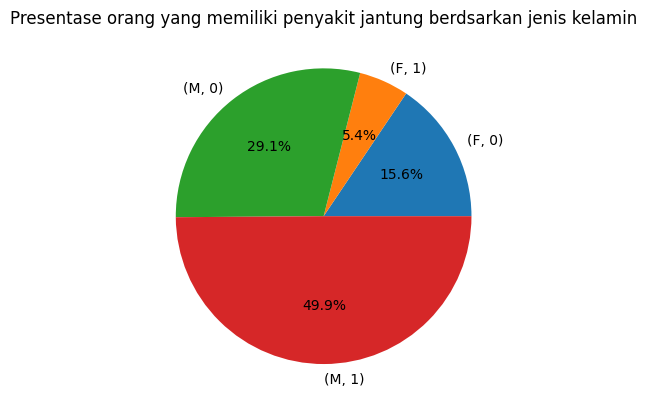

In [8]:
# groupping orang yang mengalami gagal jantung berdasarkan jenis kelamin
group = df.groupby(["Sex", "HeartDisease"]).size()

# Presentase orang yang mengalami gagal jantung berdasarkan jenis kelamin
fig, ax = plt.subplots()
group.plot.pie(ax=ax, autopct='%1.1f%%')

ax.set(title = 'Presentase orang yang memiliki penyakit jantung berdsarkan jenis kelamin')

plt.show()

Berdasarkan chart di atas, dapat diperoleh beberapa informasi berikut:
- 21% data dari keseluruhan populasi adalah perempuan (F) sementara 79% lainnya adalah laki-laki (M)
- Dari keseluruhan data sebanyak 55.3% memiliki penyakit jantung (1) dengan presentase perempuan 5.4% dan laki-laki 49.9%
- Presentase laki-laki yang memiliki penyakit jantung (1) lebih banyak dari presentase laki-laki yang tidak memiliki penyakit jantung/normal (0). Sementara itu, presentase perempuan yang memiliki penyakit jantung lebih sedikit dari presentase perempuan yang tidak memiliki penyakit jantung. Hal ini sesuai dengan uji korelasi (jenis kelamin berpengaruh terhadap target) karena laki-laki punya kemungkinan lebih besar memiliki penyakit jantung sementara perempuan tidak.

## 4.4. Distribusi target berdasarkan `Cholesterol`

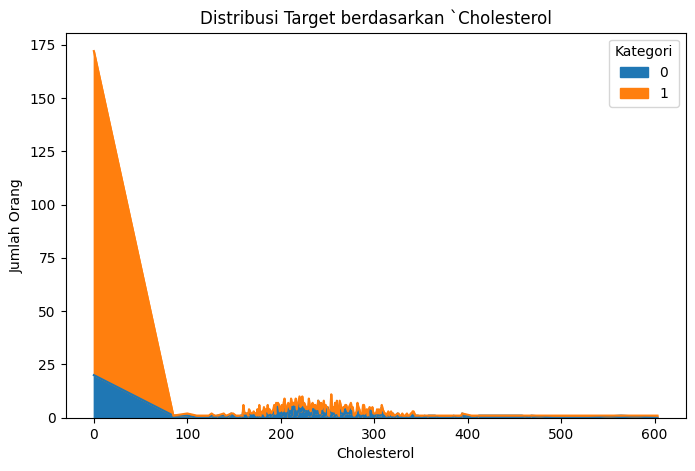

In [9]:
df_group = df.groupby(['Cholesterol', 'HeartDisease']).size().unstack(fill_value=0)

df_group.plot(kind='area', stacked=True, figsize=(8, 5))

plt.title('Distribusi Target berdasarkan `Cholesterol')
plt.xlabel('Cholesterol')
plt.ylabel('Jumlah Orang')
plt.legend(title='Kategori')
plt.show()

Dari grafik ini, terlihat bahwa kolom `Cholestrol` memiliki distribusi right skewed. Dapat dilihat juga bahwa banyak orang yang memiliki `Cholestrol` = 0. Hal ini sebetulnya tidak mungkin tejadi kecuali input 0 tersebut sebetulnya merupakan missing value

## 4.5. Distribusi target berdasarkan usia

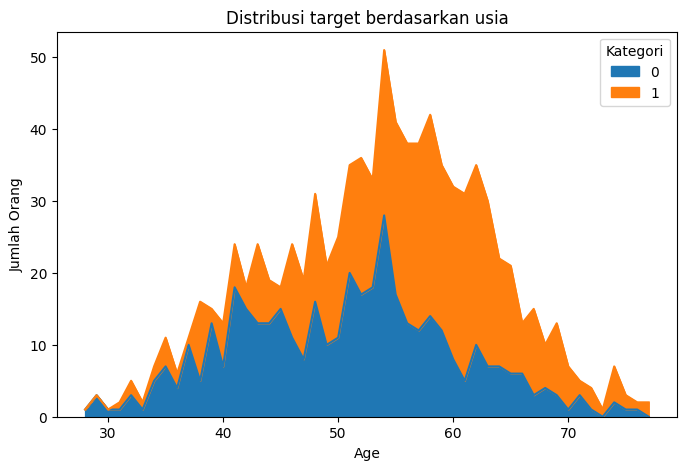

In [10]:
df_group = df.groupby(['Age', 'HeartDisease']).size().unstack(fill_value=0)

df_group.plot(kind='area', stacked=True, figsize=(8, 5))

plt.title('Distribusi target berdasarkan usia')
plt.xlabel('Age')
plt.ylabel('Jumlah Orang')
plt.legend(title='Kategori')
plt.show()

Dari grafik di atas, terlihat bahwa data usia terdistribusi secara normal. Terlihat juga bahwa orang yang memiliki serangan jantung mulai meningkat jumlahnya di usia 40-akhir dan banyak terdistribusi di usia 50-an hingga 60-an. Rentang usia tersebut perlu menjadi perhatian untuk mengecek kesehatan jantung

## 4.6. Plot `Cholesterol` vs `Age`

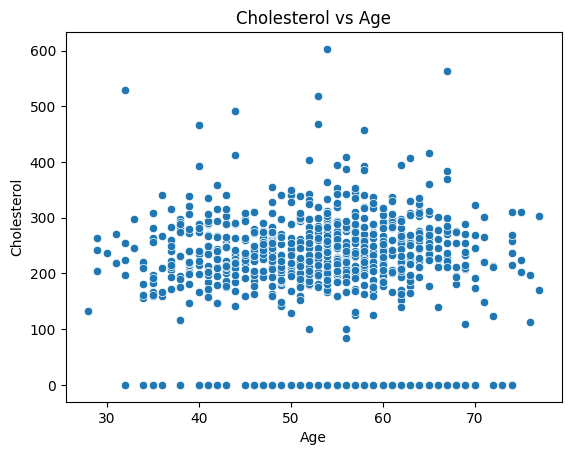

In [11]:
# scatterplot Cholesterol vs Age
sns.scatterplot(x='Age', y='Cholesterol', data=df)
plt.title('Cholesterol vs Age')
plt.show()

Pada plot di atas, tidak terlihat adanya trend peningkatan/penurunan Cholestrol seiring bertambahnya usia. Namun disini dapat terlihat jelas indikasi bahwa nilai 0 pada `Cholesterol` sebenarnya adalah missing value. Hal ini memperkuat analisis pada bagian 4.4.

## 4.7. Cek korelasi `Cholesterol` dan `ChestPainType`

Untuk fitur kategorik (`ChestPainType`) dengan fitur numerik (`Cholesterol`), uji korelasi dilakukan menggunakan [ANOVA](https://pmc.ncbi.nlm.nih.gov/articles/PMC5296382/) test dengan hipotesis:

H0: Rata-rata populasi grup `ChestPainType` sama \
H1: Rata-rata populasi grup tidak sama (setidaknya ada satu grup dengan rata-rata yang berbeda secara signifikan)

Grup disini maksudnya adalah target dikelompokkan berdasarkan unique value untuk tiap `ChestPainType`. Jadi, jika rata-rata populasi grup sama berarti `ChestPainType` tidak berpengaruh terhadap `Cholesterol`. Namun jika H0 ditolak berarti `ChestPainType` memiliki pengaruh terhadap `Cholesterol` (ada korelasi)

Pada uji hipotesis ini H0 ditolak jika p-value < 0.05

In [12]:
# uji korelasi ANOVA

group = [group['Cholesterol'].values for name, group in df.groupby('ChestPainType')]

# mengecek korelasi
f_stat, p_value = f_oneway(*group)

if p_value < 0.05:
    kesimpulan = f"p_value ({p_value}) < 0.05 sehingga ada korelasi"
else:
    kesimpulan = f"p_value ({p_value}) >= 0.05 sehingga tidak ada korelasi"

print(kesimpulan)

p_value (3.0061597329666323e-05) < 0.05 sehingga ada korelasi


Berdasarkan uji hipotesis ANOVA, diperoleh nilai p-value yang sangat kecil. Hal ini berarti `Cholesterol` memiliki korelasi dengan kolom `RestingECG`

# 5. Feature Engineering

## 5.1. Cardinality Check

Pada bagian ini akan dilihat jumlah unique value pada fitur kategorik dan apa saja unique value tersebut

In [13]:
# cardinality check
cardinality_check = []
for col in categorical:
    cardinality_check.append([col, df[col].nunique(), df[col].unique()])

pd.DataFrame(columns=['nama kolom', 'jumlah nilai unique', 'nilai unique'], data = cardinality_check)

,nama kolom,jumlah nilai unique,nilai unique
0,Sex,2,"[M, F]"
1,ChestPainType,4,"[ATA, NAP, ASY, TA]"
2,FastingBS,2,"[0, 1]"
3,RestingECG,3,"[Normal, ST, LVH]"
4,ExerciseAngina,2,"[N, Y]"
5,ST_Slope,3,"[Up, Flat, Down]"


Semua kolom kategorik termasuk low cardinality karena jumlah nilai unique hanya berkisar 2-4 saja.

## 5.2. Split Features (X) & Target (y)

Pada bagian ini dilakukan pemisahan fitur dengan kolom target (`HeartDisease`)

In [14]:
# fitur
X = df.drop(['HeartDisease'], axis = 1)

# target
y = df['HeartDisease']

# cek fitur
X

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up
...,...,...,...,...,...,...,...,...,...,...,...
913,45,M,TA,110,264,0,Normal,132,N,1.2,Flat
914,68,M,ASY,144,193,1,Normal,141,N,3.4,Flat
915,57,M,ASY,130,131,0,Normal,115,Y,1.2,Flat
916,57,F,ATA,130,236,0,LVH,174,N,0.0,Flat


## 5.3. Split Train & Test

Selanjutnya data akan dibagi menjadi data train dan data test dengan komposisi 80% : 20%

In [15]:
# pemisahan data train dan test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 2)
print('train size: ', X_train.shape)
print('test size: ', X_test.shape)

train size:  (734, 11)
test size:  (184, 11)


Data telah dibagi menjadi sebanyak 734 data untuk data train dan 184 data untuk data test

## 5.4. Analisis Outlier

Pada bagian ini akan dilakukan pengecekan outlier untuk kolom yang bersifat numerik

In [16]:
# cek skewness dari train data

listItem = []

for col in numerical:
    listItem.append([col, round(X_train[col].skew(),1), np.where(
        (round(X_train[col].skew(),1) <= 0.5) & (round(X_train[col].skew(),1)>= -0.5),
        'normal', 'skewed'
    )])

skewness = pd.DataFrame(columns=['nama kolom', 'nilai skewness', 'distribution'], data=listItem)
skewness

,nama kolom,nilai skewness,distribution
0,Age,-0.2,normal
1,RestingBP,-0.0,normal
2,Cholesterol,-0.6,skewed
3,MaxHR,-0.1,normal
4,Oldpeak,1.0,skewed


Kolom `Age`, `RestingBP`, dan `MaxHR` terdistribusi normal sedangkan kolom `Cholesterol` dan `Oldpeak` terdistribusi skewed. Selanjutnya akan dilihat batas atas, batas bawah, dan presentase banyaknya outlier untuk masing-masing kolom

In [17]:
# Melihat batas atas, batas bawah, serta presentase outlier

column = []
lower_bound = []
upper_bound = []
percent_total_outlier = []

for row in range(0, len(skewness)):
    col = skewness['nama kolom'][row]

    # cek batas atas dan batas bawah jika distribusi skewed
    if skewness['distribution'][row] == 'skewed':
        IQR = X_train[col].quantile(0.75) - X_train[col].quantile(0.25)
        lower_boundary = X_train[col].quantile(0.25) - (1.5*IQR)
        upper_boundary = X_train[col].quantile(0.75) + (1.5*IQR)

    # cek batas atas dan batas bawah jika distribusi normal
    else:
        lower_boundary = X_train[col].mean() - (3*X_train[col].std())
        upper_boundary = X_train[col].mean() + (3*X_train[col].std())

    # append ke list
    column.append(col)
    lower_bound.append(lower_boundary)
    upper_bound.append(upper_boundary)

    # cek presentase banyaknya outlier dan append ke list
    total_outlier = ((len(X_train[X_train[col] > upper_boundary])/len(X_train)*100) + (len(X_train[X_train[col]<lower_boundary])/len(X_train)*100))
    percent_total_outlier.append(total_outlier)

# data frame outlier
outliers = pd.DataFrame({
    'column': column,
    'upper_boundary': [round(upper_bound,2) for upper_bound in upper_bound],
    'lower_boundary':[round(lower_bound,2) for lower_bound in lower_bound],
    'percentage_total_outlier': [round(percent_total_outlier,2) for percent_total_outlier in percent_total_outlier]
})

# tampilkan dataframe outliers
outliers

,column,upper_boundary,lower_boundary,percentage_total_outlier
0,Age,81.82,24.91,0.00
1,RestingBP,187.35,76.85,0.54
2,Cholesterol,415.38,24.38,19.62
3,MaxHR,213.30,59.21,0.00
4,Oldpeak,3.75,-2.25,1.50


Bandingkan dengan rangkuman statistik kolom numerik

In [18]:
# statistik data numerik
X_train[numerical].describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
Age,734.0,53.37,9.48,28.0,47.0,54.0,60.00,77.0
RestingBP,734.0,132.10,18.42,0.0,120.0,130.0,140.00,200.0
Cholesterol,734.0,198.72,109.33,0.0,171.0,222.0,268.75,603.0
MaxHR,734.0,136.25,25.68,60.0,120.0,136.5,155.75,202.0
Oldpeak,734.0,0.88,1.08,-2.6,0.0,0.5,1.50,6.2


Kolom `Age` dan `MaxHR` merupakan kolom terdistribusi normal tidak memiliki data outlier. Sementara itu, kolom `RestingBP` (normal), `Cholesterol` (skewed) dan `Oldpeak` (skewed) memiliki presentase outlier masing-masing 0.54%, 19.62%, dan 1.5% dengan rincian sebagai berikut:
- `RestingBP` memiliki data outlier yang kurang dari batas bawah (terlihat dari nilai minimum: 0 < 76.85) dan melebihi batas atas (terlihat dari nilai maksimum: 200 > 187.35)
- `Cholesterol` memiliki data outlier yang kurang dari batas bawah (terlihat dari nilai minimum: 0 < 24.38) dan yang melebihi batas atas (terlihat dari nilai maksimum: 603 > 415.38)
- `Oldpeak` memiliki data outlier yang kurang dari batas bawah (terlihat dari nilai minimum: -2.6 < -2.25) dan yang melebihi batas atas (terlihat dari maksimum: 5.6 > 3.75)

Kolom `Cholestrol` memiliki outlier yang cukup banyak sehingga perlu di handling karena akan berpengaruh signifikan terhadap model.

## 5.5. Handling outlier `Cholesterol`

Jika dilihat pada grafik pada bagian 4.4. data `Cholesterol` terbanyak adalah 0. Hal ini sebenarnya tidak mungkin terjadi kecuali jika nilai 0 tersebut adalah missing value (diperkuat pada grafik pada bagian 4.6.). Oleh karena itu, outlier pada data `Cholesterol` akan di handle pada nilai 0 saja dengan melakukan imputasi. Ide awalnya adalah mengganti nilai 0 tersebut dengan rata-rata nilai berdasarkan kelompok usia pada data. Namun ternyata pada grafik di bagian 4.6. terlihat tidak adanya trend yang menunjukkan hubungan antara usia dan kolestrol. Oleh karena itu, data dikelompokkan berdasarkan variabel lain yang mungkin memiliki korelasi dengan kolestrol yaitu `ChestPainType`. Terbukti pada bagian 4.7. `Cholesterol` memiliki korelasi dengan `ChestPainType`. Selanjutnya missing value atau nilai 0 akan dihandling dengan imputasi rata-rata kolestrol untuk tiap kelompok `ChestPainType`

In [19]:
# mengubah nilai 0 menjadi missing value di kolom 'Cholesterol' dan 'RestingBP'
X_train["Cholesterol"] = X_train["Cholesterol"].replace(0, None)
X_test["Cholesterol"] = X_test["Cholesterol"].replace(0, None)

# imputasi missing value
X_train['Cholesterol'] = X_train.groupby('ChestPainType')['Cholesterol'].transform(lambda x: x.fillna(x.mean()))
X_test['Cholesterol'] = X_test.groupby('ChestPainType')['Cholesterol'].transform(lambda x: x.fillna(x.mean()))

# cek outlier data setelah imputasi
IQR = X_train['Cholesterol'].quantile(0.75) - X_train['Cholesterol'].quantile(0.25)
lower_boundary = X_train['Cholesterol'].quantile(0.25) - (1.5*IQR)
upper_boundary = X_train['Cholesterol'].quantile(0.75) + (1.5*IQR)
percentage_outlier = ((len(X_train[X_train['Cholesterol'] > upper_boundary])/len(X_train)*100) + (len(X_train[X_train['Cholesterol']<lower_boundary])/len(X_train)*100))

print(f"Presentase outlier setelah di handling adalah {percentage_outlier}%")

Presentase outlier setelah di handling adalah 4.087193460490463%


C:\Users\ASUS\AppData\Local\Temp\ipykernel_14880\2436303025.py:6: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  X_train['Cholesterol'] = X_train.groupby('ChestPainType')['Cholesterol'].transform(lambda x: x.fillna(x.mean()))
C:\Users\ASUS\AppData\Local\Temp\ipykernel_14880\2436303025.py:7: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  X_test['Cholesterol'] = X_test.groupby('ChestPainType')['Cholesterol'].transform(lambda x: x.fillna(x.mean()))


Handling outlier dengan menganggap nilai 0 sebagai missing value dan melakukan imputasi berdasarkan rata-rata kolesterol untuk tiap kelompok ChestPainType berhasil menurunkan presentase outlier dari 19.62% menjadi sekitar 4% saja

## 5.6. Split Numerical, Categorical, & Encodded

In [20]:
# list kolom numerik
num_cols = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']

# list kolom kategorik
cat_cols = ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']

# list kolom encoded
encoded_cols = ["FastingBS"]

print('Kolom numerik : ', num_cols)
print('Kolom kategorik : ', cat_cols)
print('kolom encodded : ', encoded_cols)

Kolom numerik :  ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']
Kolom kategorik :  ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']
kolom encodded :  ['FastingBS']


## 5.7. Preprocessing Pipeline

In [21]:
# Pipeline untuk kolom numerik
num_pipeline = Pipeline([('scaling', MinMaxScaler())])

In [22]:
# Pipeline untuk kolom kategorik
cat_pipeline = Pipeline([('encoding', OneHotEncoder(sparse_output = False))])

In [23]:
# pipeline preprocessing
preprocessing_pipeline = ColumnTransformer([
    ('pipe_num', num_pipeline, num_cols),
    ('pipe_cat', cat_pipeline, cat_cols),
    ], remainder = 'passthrough')

# 6. Model Definition

Pada project ini akan dibuat model K-Nearest Neighbour (KNN), Support Vector Machine (SVM), Decision Tree, Random Forest, dan Gradient Boosting

In [24]:
# pipeline base knn
pipeline_knn = Pipeline([
    ('preprocessing', preprocessing_pipeline),
    ('KNN', KNeighborsClassifier())])

# pipeline base SVM
pipeline_svm = Pipeline([
    ('preprocessing', preprocessing_pipeline),
    ('SVM', SVC())])

# pipeline base decision tree
pipeline_decisiontree = Pipeline([
    ('preprocessing', preprocessing_pipeline),
    ('decisiontree', DecisionTreeClassifier())])

# pipeline base random forest
pipeline_randomforest = Pipeline([
    ('preprocessing', preprocessing_pipeline),
    ('randomforest', RandomForestClassifier())])

# pipeline base gradient boosting
pipeline_gradientboosting = Pipeline([
    ('preprocessing',preprocessing_pipeline),
    ('gradientboosting', GradientBoostingClassifier())
])

# 7. Model Training

Pada bagian ini akan dilakukan training untuk seluruh base model

In [25]:
# train model KNN
pipeline_knn.fit(X_train, y_train)

c:\Users\ASUS\anaconda3\envs\h8_env_2\lib\site-packages\sklearn\compose\_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


Pipeline(steps=[('preprocessing',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('pipe_num',
                                                  Pipeline(steps=[('scaling',
                                                                   MinMaxScaler())]),
                                                  ['Age', 'RestingBP',
                                                   'Cholesterol', 'MaxHR',
                                                   'Oldpeak']),
                                                 ('pipe_cat',
                                                  Pipeline(steps=[('encoding',
                                                                   OneHotEncoder(sparse_output=False))]),
                                                  ['Sex', 'ChestPainType',
                                                   'RestingECG',
                                                   'ExerciseAngina',
                                                   'ST_Slope'])])),
                ('KNN', KNeighborsClassifier())])

In [26]:
# train model SVM
pipeline_svm.fit(X_train, y_train)

c:\Users\ASUS\anaconda3\envs\h8_env_2\lib\site-packages\sklearn\compose\_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


Pipeline(steps=[('preprocessing',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('pipe_num',
                                                  Pipeline(steps=[('scaling',
                                                                   MinMaxScaler())]),
                                                  ['Age', 'RestingBP',
                                                   'Cholesterol', 'MaxHR',
                                                   'Oldpeak']),
                                                 ('pipe_cat',
                                                  Pipeline(steps=[('encoding',
                                                                   OneHotEncoder(sparse_output=False))]),
                                                  ['Sex', 'ChestPainType',
                                                   'RestingECG',
                                                   'ExerciseAngina',
                                                   'ST_Slope'])])),
                ('SVM', SVC())])

In [27]:
# train model decision tree
pipeline_decisiontree.fit(X_train, y_train)

c:\Users\ASUS\anaconda3\envs\h8_env_2\lib\site-packages\sklearn\compose\_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


Pipeline(steps=[('preprocessing',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('pipe_num',
                                                  Pipeline(steps=[('scaling',
                                                                   MinMaxScaler())]),
                                                  ['Age', 'RestingBP',
                                                   'Cholesterol', 'MaxHR',
                                                   'Oldpeak']),
                                                 ('pipe_cat',
                                                  Pipeline(steps=[('encoding',
                                                                   OneHotEncoder(sparse_output=False))]),
                                                  ['Sex', 'ChestPainType',
                                                   'RestingECG',
                                                   'ExerciseAngina',
                                                   'ST_Slope'])])),
                ('decisiontree', DecisionTreeClassifier())])

In [28]:
# train model random forrest
pipeline_randomforest.fit(X_train, y_train)

c:\Users\ASUS\anaconda3\envs\h8_env_2\lib\site-packages\sklearn\compose\_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


Pipeline(steps=[('preprocessing',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('pipe_num',
                                                  Pipeline(steps=[('scaling',
                                                                   MinMaxScaler())]),
                                                  ['Age', 'RestingBP',
                                                   'Cholesterol', 'MaxHR',
                                                   'Oldpeak']),
                                                 ('pipe_cat',
                                                  Pipeline(steps=[('encoding',
                                                                   OneHotEncoder(sparse_output=False))]),
                                                  ['Sex', 'ChestPainType',
                                                   'RestingECG',
                                                   'ExerciseAngina',
                                                   'ST_Slope'])])),
                ('randomforest', RandomForestClassifier())])

In [29]:
# train gradient boosting
pipeline_gradientboosting.fit(X_train, y_train)

c:\Users\ASUS\anaconda3\envs\h8_env_2\lib\site-packages\sklearn\compose\_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


Pipeline(steps=[('preprocessing',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('pipe_num',
                                                  Pipeline(steps=[('scaling',
                                                                   MinMaxScaler())]),
                                                  ['Age', 'RestingBP',
                                                   'Cholesterol', 'MaxHR',
                                                   'Oldpeak']),
                                                 ('pipe_cat',
                                                  Pipeline(steps=[('encoding',
                                                                   OneHotEncoder(sparse_output=False))]),
                                                  ['Sex', 'ChestPainType',
                                                   'RestingECG',
                                                   'ExerciseAngina',
                                                   'ST_Slope'])])),
                ('gradientboosting', GradientBoostingClassifier())])

# 8. Model Evaluation

Evaluasi tiap model akan dilakukan dengan cross validation. Lalu, base model akan di evaluasi untuk menentukan model mana yang perlu Hyperparameter Tuning

## 8.1. Cross Validation

In [30]:
# Cross Validation KNN

f1_train_cross_val = cross_validate(pipeline_knn,
                                     X_train,
                                     y_train,
                                     cv=3,
                                     return_train_score=True,
                                     scoring='f1'
                                     )

print('F1 Score - All - Cross Validation For Train set : ', f1_train_cross_val['train_score'])
print('F1 Score - Mean - Cross Validation For Train set: ', f1_train_cross_val['train_score'].mean())
print('F1 Score - Std - Cross Validation For Train set: ', f1_train_cross_val['train_score'].std())
print('------')
print('F1 Score - All - Cross Validation  : ', f1_train_cross_val['test_score'])
print('F1 Score - Mean - Cross Validation : ', f1_train_cross_val['test_score'].mean())
print('F1 Score - Std - Cross Validation  : ', f1_train_cross_val['test_score'].std())

F1 Score - All - Cross Validation For Train set :  [0.90230906 0.89369369 0.89399293]
F1 Score - Mean - Cross Validation For Train set:  0.8966652283901498
F1 Score - Std - Cross Validation For Train set:  0.003992659992328097
------
F1 Score - All - Cross Validation  :  [0.87142857 0.86428571 0.87179487]
F1 Score - Mean - Cross Validation :  0.8691697191697192
F1 Score - Std - Cross Validation  :  0.0034567491250041553


In [31]:
# Cross Validation SVM

f1_train_cross_val = cross_validate(pipeline_svm,
                                     X_train,
                                     y_train,
                                     cv=3,
                                     return_train_score=True,
                                     scoring='f1'
                                     )

print('F1 Score - All - Cross Validation For Train set : ', f1_train_cross_val['train_score'])
print('F1 Score - Mean - Cross Validation For Train set: ', f1_train_cross_val['train_score'].mean())
print('F1 Score - Std - Cross Validation For Train set: ', f1_train_cross_val['train_score'].std())
print('------')
print('F1 Score - All - Cross Validation  : ', f1_train_cross_val['test_score'])
print('F1 Score - Mean - Cross Validation : ', f1_train_cross_val['test_score'].mean())
print('F1 Score - Std - Cross Validation  : ', f1_train_cross_val['test_score'].std())

F1 Score - All - Cross Validation For Train set :  [0.8972973  0.90391459 0.89716312]
F1 Score - Mean - Cross Validation For Train set:  0.8994583362040015
F1 Score - Std - Cross Validation For Train set:  0.0031515238922275876
------
F1 Score - All - Cross Validation  :  [0.86346863 0.87142857 0.86120996]
F1 Score - Mean - Cross Validation :  0.8653690568425766
F1 Score - Std - Cross Validation  :  0.0043828214363620275


In [32]:
# Cross Validation decision tree

f1_train_cross_val = cross_validate(pipeline_decisiontree,
                                     X_train,
                                     y_train,
                                     cv=3,
                                     return_train_score=True,
                                     scoring='f1'
                                     )

print('F1 Score - All - Cross Validation For Train set : ', f1_train_cross_val['train_score'])
print('F1 Score - Mean - Cross Validation For Train set: ', f1_train_cross_val['train_score'].mean())
print('F1 Score - Std - Cross Validation For Train set: ', f1_train_cross_val['train_score'].std())
print('------')
print('F1 Score - All - Cross Validation  : ', f1_train_cross_val['test_score'])
print('F1 Score - Mean - Cross Validation : ', f1_train_cross_val['test_score'].mean())
print('F1 Score - Std - Cross Validation  : ', f1_train_cross_val['test_score'].std())

F1 Score - All - Cross Validation For Train set :  [1. 1. 1.]
F1 Score - Mean - Cross Validation For Train set:  1.0
F1 Score - Std - Cross Validation For Train set:  0.0
------
F1 Score - All - Cross Validation  :  [0.79562044 0.77902622 0.81343284]
F1 Score - Mean - Cross Validation :  0.7960264970018548
F1 Score - Std - Cross Validation  :  0.014049377535503659


In [33]:
# Cross Validation random forest

f1_train_cross_val = cross_validate(pipeline_randomforest,
                                     X_train,
                                     y_train,
                                     cv=3,
                                     return_train_score=True,
                                     scoring='f1'
                                     
                                     )

print('F1 Score - All - Cross Validation For Train set : ', f1_train_cross_val['train_score'])
print('F1 Score - Mean - Cross Validation For Train set: ', f1_train_cross_val['train_score'].mean())
print('F1 Score - Std - Cross Validation For Train set: ', f1_train_cross_val['train_score'].std())
print('------')
print('F1 Score - All - Cross Validation  : ', f1_train_cross_val['test_score'])
print('F1 Score - Mean - Cross Validation : ', f1_train_cross_val['test_score'].mean())
print('F1 Score - Std - Cross Validation  : ', f1_train_cross_val['test_score'].std())

F1 Score - All - Cross Validation For Train set :  [1. 1. 1.]
F1 Score - Mean - Cross Validation For Train set:  1.0
F1 Score - Std - Cross Validation For Train set:  0.0
------
F1 Score - All - Cross Validation  :  [0.88652482 0.88888889 0.88086643]
F1 Score - Mean - Cross Validation :  0.885426712525568
F1 Score - Std - Cross Validation  :  0.0033659433732687325


In [34]:
# Cross Validation Gradient Boosting

f1_train_cross_val = cross_validate(pipeline_gradientboosting,
                                     X_train,
                                     y_train,
                                     cv=3,
                                     return_train_score=True,
                                     scoring='f1'
                                     )

print('F1 Score - All - Cross Validation For Train split : ', f1_train_cross_val['train_score'])
print('F1 Score - Mean - Cross Validation For Train split: ', f1_train_cross_val['train_score'].mean())
print('F1 Score - Std - Cross Validation For Train split: ', f1_train_cross_val['train_score'].std())
print('------')
print('F1 Score - All - Cross Validation for Test split  : ', f1_train_cross_val['test_score'])
print('F1 Score - Mean - Cross Validation for Test split : ', f1_train_cross_val['test_score'].mean())
print('F1 Score - Std - Cross Validation for Test split  : ', f1_train_cross_val['test_score'].std())

F1 Score - All - Cross Validation For Train split :  [0.97833935 0.9676259  0.98025135]
F1 Score - Mean - Cross Validation For Train split:  0.9754055319867277
F1 Score - Std - Cross Validation For Train split:  0.005556134523362866
------
F1 Score - All - Cross Validation for Test split  :  [0.87455197 0.86619718 0.87912088]
F1 Score - Mean - Cross Validation for Test split :  0.8732900111818784
F1 Score - Std - Cross Validation for Test split  :  0.005351005343138715


Dari kelima model tersebut terlihat bahwa decision tree dan random forest menghasilkan model yang overfit karena rata-rata train scorenya sempurna. Hal ini membuat model cenderung untuk menghafal data dan akan kebingungan jika bertemu dengan data dengan karakteristik yang baru. Untuk gradient boost terlihat juga bahwa perbedaan rata-rata train score dan rata-rata test score dari cross validation cukup jauh sehingga model dapat dikatakan overfit juga. Oleh karena itu, dari kelima model menyisakan KNN dan SVM yang dapat dikatakan sebagai good fit. Model SVM efektif jika jumlah fitur lebih banyak dari jumlah sampel. Sementara pada data ini, jumlah fitur tidak lebih banyak dari jumlah sampel. Oleh karena itu, pada kasus ini KNN akan dipilih sebagai model untuk hyperparameter tuning.

## 8.2. Hyperparameter Tuning Model KNN

Tuning model knn dilakukan untuk hyperparameter n_neighbors, weights, dan metric

In [35]:
# hyperparameter tuning dengan Grid Search

grid_search_params = {'KNN__n_neighbors': [3, 5, 7, 9, 11, 13, 15], 
                      'KNN__weights': ['uniform', 'distance'],
                      'KNN__metric': ['euclidean', 'manhattan']}

grid_search = GridSearchCV(pipeline_knn, param_grid = grid_search_params, cv = 3)
grid_search.fit(X_train, y_train)

c:\Users\ASUS\anaconda3\envs\h8_env_2\lib\site-packages\sklearn\compose\_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


GridSearchCV(cv=3,
             estimator=Pipeline(steps=[('preprocessing',
                                        ColumnTransformer(remainder='passthrough',
                                                          transformers=[('pipe_num',
                                                                         Pipeline(steps=[('scaling',
                                                                                          MinMaxScaler())]),
                                                                         ['Age',
                                                                          'RestingBP',
                                                                          'Cholesterol',
                                                                          'MaxHR',
                                                                          'Oldpeak']),
                                                                        ('pipe_cat',
                                                                         Pipeline(steps=[('encoding',
                                                                                          OneHotEncoder(sparse_output=False))]),
                                                                         ['Sex',
                                                                          'ChestPainType',
                                                                          'RestingECG',
                                                                          'ExerciseAngina',
                                                                          'ST_Slope'])])),
                                       ('KNN', KNeighborsClassifier())]),
             param_grid={'KNN__metric': ['euclidean', 'manhattan'],
                         'KNN__n_neighbors': [3, 5, 7, 9, 11, 13, 15],
                         'KNN__weights': ['uniform', 'distance']})

## 8.3 Model KNN terbaik

In [36]:
# melihat parameter model KNN terbaik
best_params = grid_search.best_params_
best_params

{'KNN__metric': 'manhattan', 'KNN__n_neighbors': 13, 'KNN__weights': 'uniform'}

In [37]:
best_estimator = grid_search.best_estimator_
best_estimator

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('pipe_num',
                                                  Pipeline(steps=[('scaling',
                                                                   MinMaxScaler())]),
                                                  ['Age', 'RestingBP',
                                                   'Cholesterol', 'MaxHR',
                                                   'Oldpeak']),
                                                 ('pipe_cat',
                                                  Pipeline(steps=[('encoding',
                                                                   OneHotEncoder(sparse_output=False))]),
                                                  ['Sex', 'ChestPainType',
                                                   'RestingECG',
                                                   'ExerciseAngina',
                                                   'ST_Slope'])])),
                ('KNN',
                 KNeighborsClassifier(metric='manhattan', n_neighbors=13))])

Setelah dilakukan hyperparameter tuning, kombinasi hyperparameter terbaik untuk model KNN dalam kasus ini adalah:
- n_neighbors = 13
- weights = 'uniform'
- metric = 'manhattan

In [38]:
# fungsi untuk mengecek performa model

def performance_check(clf, X, y):
  y_pred = clf.predict(X)

  return classification_report(y, y_pred)

# Evaluasi model terbaik
print(performance_check(best_estimator, X_train, y_train))
print(performance_check(best_estimator, X_test, y_test))

              precision    recall  f1-score   support

           0       0.85      0.84      0.84       321
           1       0.88      0.89      0.88       413

    accuracy                           0.87       734
   macro avg       0.86      0.86      0.86       734
weighted avg       0.86      0.87      0.86       734

              precision    recall  f1-score   support

           0       0.87      0.83      0.85        89
           1       0.85      0.88      0.87        95

    accuracy                           0.86       184
   macro avg       0.86      0.86      0.86       184
weighted avg       0.86      0.86      0.86       184



# 9. Model Saving

Model KNN terbaik akan disimpan untuk data inferencing

In [41]:
with open('model_pipeline.pkl', 'wb') as file_1:
  pickle.dump(pipeline_knn, file_1)

## 10. Model Inference

Model inference dilakukan pada notebook 'inference.ipynb'

## 11. Kesimpulan